# MoE comparisons: four heads on a shared, frozen backbone

**What it does.** Classifies 64x64 images into 200 classes. A small ResNet *backbone* is trained once and then **frozen**; four different *heads* are trained on top of it and compared on the validation set:

| model | idea |
|---|---|
| **CNN** | baseline: one ordinary dense layer |
| **MoE** | several small expert networks and a *gate* that decides how much each expert counts for an image |
| **pMoE** | each expert looks only at the few image patches its router picks |
| **MGE** | one expert on each depth of the backbone (shallow, middle, deep); their answers are averaged |

**How to run**
1. Open the notebook on a machine with a GPU if you can (RunPod, Colab or local, see the README).
2. Run the cells from top to bottom. The cells you may want to edit are **Settings** and **Choose the backbone**.
3. In **Choose the backbone**, write the path of a saved backbone in `BACKBONE_PATH`, or leave it `None` to train a new one (it is saved under an automatic name in `MoE_comparisons/models/`).
4. Each model writes a log to `MoE_comparisons/history_logs/` and, at the end, its weights to `MoE_comparisons/models/`. To retrain a single model, run only its cell: the backbone is not trained again.

Only the **validation** split is used here. The test split is not touched.

This notebook does not depend on any other notebook: `pMoE_MGE_finetune_v2.ipynb` can use a backbone saved here by writing its path, and the other way round.

In [1]:
import os, sys, subprocess
import warnings
warnings.filterwarnings('ignore')
os.environ.setdefault('TF_FORCE_GPU_ALLOW_GROWTH', 'true')   # take GPU memory as needed, not all of it at start (kernels can then share a GPU)

REPO_URL = 'https://github.com/durak-dev/ImageClassification.git'
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    # Colab starts with an empty VM: clone the repo (code AND data live in it).
    # On later runs the folder already exists, so just pull the newest commits.
    ROOT = '/content/ImageClassification'
    if not os.path.exists(ROOT):
        subprocess.run(['git', 'clone', REPO_URL, ROOT], check=True)
    else:
        # fetch + hard reset instead of `pull`: always lands on the newest origin commit, even if the VM copy diverged
        subprocess.run(['git', '-C', ROOT, 'fetch', 'origin'], check=True)
        subprocess.run(['git', '-C', ROOT, 'reset', '--hard', '@{u}'], check=True)
else:
    # Local: the notebook sits in the project root, but also work if it was
    # started from a subfolder.
    cwd = os.path.abspath(os.getcwd())
    ROOT = cwd if os.path.isdir(os.path.join(cwd, 'utils')) else os.path.dirname(cwd)

os.chdir(ROOT)
sys.path.insert(0, ROOT)          # so `import utils.funcs` finds OUR utils folder

DATA_DIR = os.path.join(ROOT, 'data')
ORIG_DIR = os.path.join(DATA_DIR, 'original')            # raw images/ + labels/ (placed manually, never modified)
MANIFEST_PATH = os.path.join(DATA_DIR, 'split_manifest.csv')   # which file belongs to which split
SEED = 42
NB_DIR = 'MoE_comparisons'   # this notebook's output folder (relative to the project root)
MODELS_DIR = f'{NB_DIR}/models'          # backbones and head weights
HISTORY_DIR = f'{NB_DIR}/history_logs'   # one CSV log per training run
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(HISTORY_DIR, exist_ok=True)
print('Running on:', 'Google Colab' if IN_COLAB else 'local machine')
print('Project root:', ROOT)

Running on: local machine
Project root: /workspace/ImageClassification


In [ ]:
# the kernel survives between runs: drop every cached utils module so the code git just pulled is what gets imported
for _m in [m for m in sys.modules if m == 'utils' or m.startswith('utils.')]:
    del sys.modules[_m]
from utils.funcs import *
from utils import config, github_sync, plotting, resnet
from utils.github_sync import save_csv, load_csv, push_files
from utils.MoE import *

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import f1_score

I0000 00:00:1795033447.713768     767 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795033447.744286     767 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795033448.525943     767 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### Where the results go
Logs go to `MoE_comparisons/history_logs/`, backbones and model weights to `MoE_comparisons/models/` (this notebook's own output folder). A RunPod pod or Colab VM loses its disk when it ends, so the next cell offers two ways to keep them:
* **Push to GitHub:** paste a GitHub token into the box (hidden, kept in memory only). Everything is then committed to the `checkpoints` branch as soon as it is written, and a new pod downloads the saved backbone from there instead of training it again. Leave the box empty to skip.
* **Copy to your PC:** run `.\pull_results.ps1 -Ip <ip> -Port <port>` before you terminate the pod (see the README).

Running locally you can ignore this cell: everything stays in the project folder.

In [3]:
# Is the disk temporary? Colab VM, or a RunPod pod (pod_bootstrap.sh clones the repo into /workspace).
ON_POD = ROOT.startswith('/workspace/') or bool(os.environ.get('RUNPOD_POD_ID'))
REMOTE = IN_COLAB or ON_POD
if REMOTE:
    config.ensure_github()      # asks once for a GitHub token (hidden box, kept in memory only); empty = no upload
USE_GITHUB = REMOTE and config.github_ready()

if USE_GITHUB:
    _, repo, branch = config.github_settings()
    print(f'Results -> GitHub {repo}@{branch}: every log, backbone and weight file is committed when it is written')
elif ON_POD:
    print('Results stay on the pod. Copy them to your PC before terminating it:  .\\pull_results.ps1 -Ip <ip> -Port <port>')
else:
    print(f'Results -> local folders ({HISTORY_DIR}/, {MODELS_DIR}/)')

Results stay on the pod. Copy them to your PC before terminating it:  .\pull_results.ps1 -Ip <ip> -Port <port>


In [4]:
# Recreate data/{split}/ with the corrected images + labels if they are missing (fresh Colab VM).
# Needs split_manifest.csv, data/original/ and the two checkpoint files from the cloned repo.
if not all(os.path.exists(os.path.join(split_dir(DATA_DIR, s, 'labels'), CORRECTED_LABELS_FILE)) for s in SPLITS):
    materialize_splits(ORIG_DIR, DATA_DIR, pd.read_csv(MANIFEST_PATH))
    rebuild_corrected(pd.read_csv(os.path.join(ROOT, 'checkpoints', 'df_fixed.csv')), DATA_DIR,
                      labels_corrected=pd.read_csv(os.path.join(ROOT, 'checkpoints', 'labels_corrected.csv')))

train: 42000 images
val  : 9000 images
test : 9000 images
test : 9000 images written, 3724 of 9000 corrected -> /workspace/ImageClassification/data/test/images_corrected
train: 42000 images written, 17469 of 42000 corrected -> /workspace/ImageClassification/data/train/images_corrected
val  : 9000 images written, 3906 of 9000 corrected -> /workspace/ImageClassification/data/val/images_corrected
labels_corrected.csv written for test, train, val


In [5]:
dfs = {s: pd.read_csv(os.path.join(split_dir(DATA_DIR, s, "labels"), CORRECTED_LABELS_FILE)) for s in ["train", "val", "test"]}
classes = sorted(dfs["train"]["class_id"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

## Data
Images are resized to 64x64. **Only the training set is rebalanced** (classes with few images are repeated up to the median class size); validation and test stay as they are.

In [6]:
SIZE, BATCH, AUTOTUNE = 64, 128, tf.data.AUTOTUNE
CLASS_BALANCE = 'oversample'         # train set only: None | "oversample" | "undersample"  (see funcs.balance_frame)
CLASS_BALANCE_TARGET = 'median'  # images per class: None (max / min) | "min" | "median" | "max" | int

def load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return tf.image.resize(img, (SIZE, SIZE)), y

def make_ds(split, shuffle):
    df = dfs[split]
    if split == "train" and CLASS_BALANCE:      # never resample val / test
        df = balance_frame(df, CLASS_BALANCE, CLASS_BALANCE_TARGET, seed=SEED)
        n = df["class_id"].value_counts()
        print(f"train balanced ({CLASS_BALANCE}): {len(df)} images, {n.min()}-{n.max()} per class")
    paths = (f"{DATA_DIR}/{split}/images_corrected/" + df["filename"].astype(str)).values
    labels = df["class_id"].map(class_to_idx)
    assert labels.notna().all(), f"{split} has labels not present in train"
    ds = tf.data.Dataset.from_tensor_slices((paths, labels.values.astype("int32")))
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED)
    return ds.map(load, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train, val, test = make_ds("train", True), make_ds("val", False), make_ds("test", False)
print(len(classes), "classes")
print(dfs["train"]["filename"].iloc[0], os.path.exists(f"{DATA_DIR}/train/images_corrected/" + str(dfs["train"]["filename"].iloc[0])))
for x, y in train.take(1):
    print(x.shape, x.dtype, float(tf.reduce_min(x)), float(tf.reduce_max(x)))

train balanced (oversample): 38600 images, 193-193 per class


I0000 00:00:1795033696.248545     767 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22151 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4090, pci bus id: 0000:02:00.0, compute capability: 8.9


200 classes
image_000002.JPEG True
(128, 64, 64, 3) <dtype: 'float32'> 0.0 255.0


## Settings
Everything you might want to change is in the next cell.

* **Backbone** (only used when `BACKBONE_PATH = None`) - `drop` is the dropout inside the backbone and `weight_decay` the AdamW weight decay. Raise them if the backbone overfits.
* **Heads** - every model trains only its own head on top of the frozen backbone, for at most `EPOCHS` epochs. Training stops early when the validation loss has not improved for 8 epochs.

In [ ]:
# ======== Settings ========

# --- backbone training (only used when BACKBONE_PATH = None)
BACKBONE = dict(
    drop=0.3,           # dropout inside the backbone (after stages 2 and 3)
    head_drop=0.3,      # dropout of the linear head used only for pretraining
    epochs=40,     # pretraining epochs (early stopping usually stops earlier)
    lr=1e-3,       # pretraining learning rate
    weight_decay=1e-4,  # AdamW weight decay
)

# --- heads: every model trains its own head on the frozen backbone
EPOCHS = 20               # head training epochs (early stopping, patience 8)
LR = 1e-3                 # head learning rate
USE_AUG = True            # random flip + shift for every model
FEATURE_DROP = 0.3        # CNN / MoE: dropout on the 256 pooled features
N_EXPERTS = 4             # MoE / pMoE: number of experts
BALANCE = 0.05            # MoE: weight of the load-balancing loss
L_PATCHES = 8             # pMoE: patches each expert keeps (at most 64)
DIVERSITY_WEIGHT = 0.1    # MGE: weight of the diversity penalty

aug = tf.keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomTranslation(0.1, 0.1)])
AUG = aug if USE_AUG else None


def run(model, name, epochs=EPOCHS, gate=False):
    """Train with the default callbacks (val macro-F1, CSV log, early stopping) and save <HISTORY_DIR>/<name>.csv."""
    cbs, mon = default_callbacks(val, name=name, log_dir=HISTORY_DIR, gate=gate)
    history = model.fit(train, validation_data=val, epochs=epochs, callbacks=cbs)
    if USE_GITHUB:
        push_files({f'{HISTORY_DIR}/{name}.csv': os.path.join(HISTORY_DIR, f'{name}.csv')}, f'history log: {name}')
    plot_history(history)
    return history, mon

## The backbone
A ResNet written for 64x64 images (no early downsampling). Its code is the function `backbone` in the first code cell below, so you can change it right there (layers, widths, number of blocks). It has four stages; the outputs of stages 2, 3 and 4 (`s1`, `s2`, `s3`) are what the heads use:

```
image 64x64 -> augmentation -> stem -> stage 1 -> stage 2 (s1: 32x32x64) -> stage 3 (s2: 16x16x128) -> stage 4 (s3: 8x8x256)
```

| model | reads |
|---|---|
| CNN, MoE | `s3`, averaged to 256 numbers |
| pMoE | `s3` as 64 patches (the 8x8 grid) of 256 numbers |
| MGE | `s1`, `s2` and `s3` |

A saved backbone is a complete `.keras` model (layers and weights), so it can be loaded without this code: editing `backbone` only matters when you train a **new** backbone, and old files keep the layers they were trained with. The cell after the code defines `train_backbone()` (a plain linear head); the one after that chooses the backbone all heads use.

In [ ]:
# The backbone: edit it freely. It must return [s1, s2, s3] (shallow -> deep); the settings come from BACKBONE above.
# Only used when training a NEW backbone: a saved backbone carries its own layers, so editing this cell does not change it.
# (It replaces the default `backbone` of utils/MoE.py, which is not used here.)
def backbone(inp):
    """Conv layers only (no augmentation) -> [s1, s2, s3], shallow -> deep."""
    drop = BACKBONE['drop']
    x = layers.Rescaling(1 / 255)(inp)
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(x)     # stem
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # stage 1: 64 x 64 x 32, no downsampling
    for _ in range(3):
        x = res_block(x, 32, downsample=False)

    # stage 2: 32 x 32 x 64
    x = res_block(x, 64)
    for _ in range(5):
        x = res_block(x, 64, downsample=False)
    s1 = x                                        # MGE expert 0
    x = layers.SpatialDropout2D(drop)(x)

    # stage 3: 16 x 16 x 128
    x = res_block(x, 128)
    for _ in range(7):
        x = res_block(x, 128, downsample=False)
    s2 = x                                        # MGE expert 1
    x = layers.SpatialDropout2D(drop)(x)

    # stage 4: 8 x 8 x 256
    x = res_block(x, 256)
    for _ in range(2):
        x = res_block(x, 256, downsample=False)
    s3 = x                                        # MGE expert 2, pMoE, CNN / MoE (pooled)

    return [s1, s2, s3]

In [ ]:
# Train a NEW backbone (only runs when BACKBONE_PATH is None in the cell below).
# It is trained with a plain linear head, then saved as a complete .keras file (layers + weights) in MODELS_DIR under an
# automatic, unique name. A file is never overwritten.
def train_backbone():
    tf.keras.backend.clear_session()
    trunk = resnet.make_trunk(SIZE, backbone)
    path = resnet.new_trunk_path(MODELS_DIR, trunk)
    inp = tf.keras.Input((SIZE, SIZE, 3))
    x = AUG(inp) if AUG is not None else inp
    x = layers.GlobalAveragePooling2D()(trunk(x)[-1])
    x = layers.Dropout(BACKBONE['head_drop'])(x)
    pre = tf.keras.Model(inp, layers.Dense(len(classes))(x), name='pretrain')
    pre.compile(tf.keras.optimizers.AdamW(BACKBONE['lr'], weight_decay=BACKBONE['weight_decay']),
                tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])
    run(pre, resnet.trunk_name(path) + '_pretrain', epochs=BACKBONE['epochs'])
    resnet.save_trunk(trunk, path)                  # best epoch: EarlyStopping restored the best weights
    print(f'saved {os.path.getsize(path) / 1e6:.1f} MB -> {path}')
    if USE_GITHUB:
        push_files({path: path}, f'backbone: {path}')
    tf.keras.backend.clear_session()
    return path


## Choose the backbone
`BACKBONE_PATH` decides which backbone every head below is trained on, and the backbone is **frozen**: no run changes it, so every head sees exactly the same features.

* `BACKBONE_PATH = 'MoE_comparisons/models/<file>.keras'` (path relative to the project folder) loads that backbone. It can come from either notebook.
* `BACKBONE_PATH = None` trains a new backbone first (the code above), saves it in this notebook's `models/` folder under an automatic name and prints that name, so you can paste it here next time. Files are never overwritten.

The file name goes into the log names, so runs on different backbones never overwrite each other.

In [ ]:
# The backbone EVERY head below is trained on. It is FROZEN: no run changes it.
#   path -> load that backbone, e.g. 'MoE_comparisons/models/backbone_6072k_20251118-210000.keras'
#   None -> train a NEW backbone now (saved in MoE_comparisons/models/ under an automatic name, printed below)
BACKBONE_PATH = None

if BACKBONE_PATH is None:
    BACKBONE_PATH = train_backbone()
    print(f'To reuse it later, write  BACKBONE_PATH = {BACKBONE_PATH!r}')

resnet.fetch_if_missing(BACKBONE_PATH, USE_GITHUB)         # a new pod: download it from GitHub
BACKBONE_ID = resnet.trunk_name(BACKBONE_PATH)             # part of every log name
assert resnet.trunk_size(BACKBONE_PATH) == SIZE, f'{BACKBONE_PATH} was trained on other image sizes than SIZE = {SIZE}'

BB = resnet.make_frozen_backbones(BACKBONE_PATH, feature_drop=FEATURE_DROP)
_inp = tf.keras.Input((SIZE, SIZE, 3))
print('using the frozen backbone', BACKBONE_PATH)
print('feature maps (H, W, C):', [tuple(m.shape[1:]) for m in BB.maps(_inp)])
del _inp
tf.keras.backend.clear_session()


## 1. CNN (baseline)
```
backbone (s3) -> average over the 8x8 grid -> 256 numbers -> dropout -> Dense(N_EXPERTS x 128, ReLU) -> dropout -> Dense(200)
```
The hidden layer has as many units as all MoE experts together, so the MoE has no extra capacity compared with this baseline.

Epoch 1/20


E0000 00:00:1795034642.872470     767 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/trunk_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.1333 - loss: 4.2406  val macro-F1 0.1637
302/302 ━━━━━━━━━━━━━━━━━━━━ 35s 87ms/step - accuracy: 0.1334 - loss: 4.2391 - val_accuracy: 0.1977 - val_loss: 3.8378 - val_f1: 0.1637
Epoch 2/20
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.2259 - loss: 3.5962  val macro-F1 0.1816
302/302 ━━━━━━━━━━━━━━━━━━━━ 25s 82ms/step - accuracy: 0.2259 - loss: 3.5958 - val_accuracy: 0.2080 - val_loss: 3.8086 - val_f1: 0.1816
Epoch 3/20
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.2587 - loss: 3.3953  val macro-F1 0.1651
302/302 ━━━━━━━━━━━━━━━━━━━━ 25s 82ms/step - accuracy: 0.2586 - loss: 3.3960 - val_accuracy: 0.1967 - val_loss: 3.8720 - val_f1: 0.1651
Epoch 4/20
302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.2835 - loss: 3.2675  val macro-F1 0.1857
302/302 ━━━━━━━━━━━━━━━━━━━━ 25s 84ms/step - accuracy: 0.2835 - loss: 3.2675 - val_accuracy: 0.2180 - val_loss: 3.7867 - val_f1: 0.1857
Epoch 5/20
301/302 ━━━━━━━━━━━━━━━━

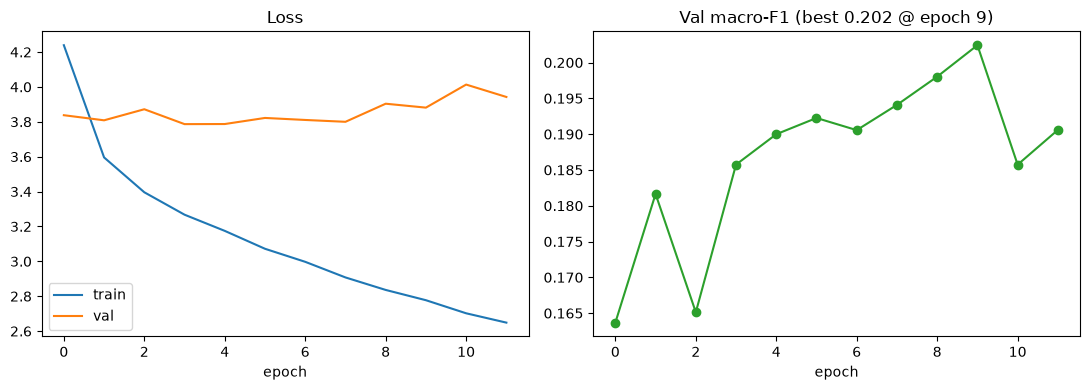

In [ ]:
tf.keras.backend.clear_session()
cnn = build_cnn(SIZE, len(classes), n_experts=N_EXPERTS, augmentation=AUG, backbone_fn=BB.pooled, lr=LR)
hist_cnn, _ = run(cnn, f'cnn_{EPOCHS}epochs_{BACKBONE_ID}')

## 2. MoE (soft mixture of experts)
```
256 numbers -> gate:      Dense(N_EXPERTS, softmax)                 -> one weight per expert (they sum to 1)
            -> expert i:  Dense(128, ReLU) -> dropout -> Dense(200) -> class scores
output = sum over experts of  gate weight x expert scores
```
* Every expert runs on every image; the gate only decides how much each one counts.
* A **load-balancing loss** (weight `BALANCE`) rewards using all experts equally. Without it the gate tends to rely on one or two experts.
* While training, the notebook prints the average gate weight per expert (`usage`) and how often each expert has the largest weight (`wins`).

Epoch 1/20


E0000 00:00:1795034956.085613     767 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_4_1/trunk_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.0976 - loss: 4.5514  usage [0.26 0.17 0.2  0.38]  wins [ 778  224  409 1149]
  val macro-F1 0.1240
302/302 ━━━━━━━━━━━━━━━━━━━━ 38s 91ms/step - accuracy: 0.0977 - loss: 4.5507 - val_accuracy: 0.1640 - val_loss: 4.1207 - val_f1: 0.1240
Epoch 2/20
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.1928 - loss: 3.8460  usage [0.25 0.17 0.27 0.31]  wins [789 193 705 873]
  val macro-F1 0.1626
302/302 ━━━━━━━━━━━━━━━━━━━━ 26s 86ms/step - accuracy: 0.1927 - loss: 3.8469 - val_accuracy: 0.2016 - val_loss: 3.8792 - val_f1: 0.1626
Epoch 3/20
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.2307 - loss: 3.6116  usage [0.24 0.18 0.31 0.27]  wins [ 667  300 1010  583]
  val macro-F1 0.1756
302/302 ━━━━━━━━━━━━━━━━━━━━ 26s 85ms/step - accuracy: 0.2307 - loss: 3.6115 - val_accuracy: 0.1996 - val_loss: 3.9278 - val_f1: 0.1756
Epoch 4/20
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.2571 - loss: 3.4538  usage [0.25 0.24 0.28

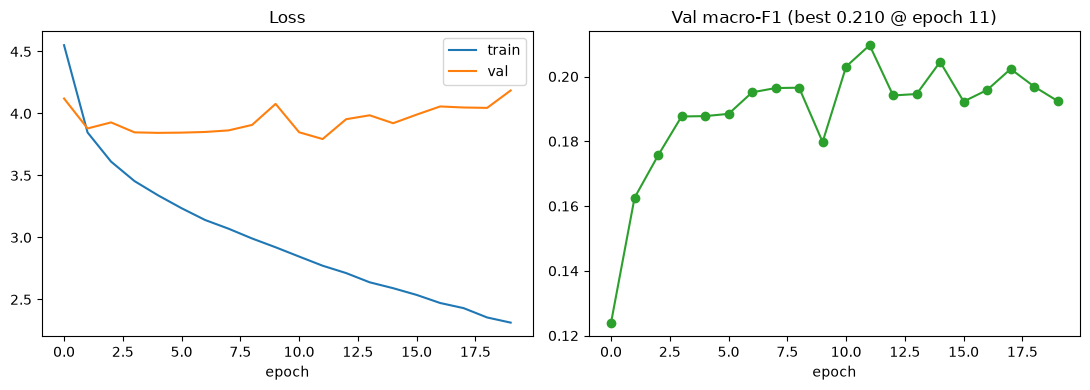

In [ ]:
tf.keras.backend.clear_session()
moe_model = build_moe(SIZE, len(classes), n_experts=N_EXPERTS, balance=BALANCE, augmentation=AUG, backbone_fn=BB.pooled, lr=LR)
hist_moe, mon_moe = run(moe_model, f'moe_{EPOCHS}epochs_{BACKBONE_ID}', gate=True)

The plot shows how the gate spreads the images over the experts: left, the average weight of each expert per epoch; right, how even that spread is (1 = all experts equal, 0 = a single expert).

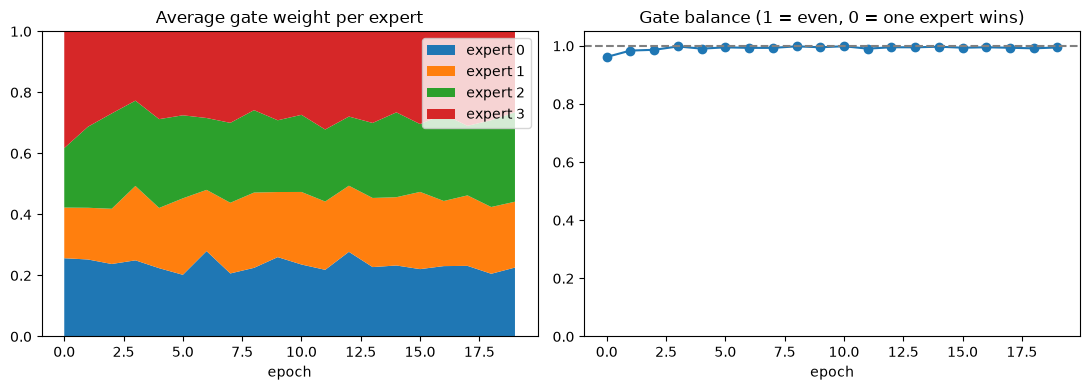

In [ ]:
mon = mon_moe
usage = np.array(mon.usage)                      # (epochs, experts)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].stackplot(range(len(usage)), usage.T, labels=[f"expert {i}" for i in range(usage.shape[1])])
ax[0].set(title="Average gate weight per expert", xlabel="epoch", ylim=(0, 1))
ax[0].legend(loc="upper right")

ax[1].plot(mon.entropy, marker="o")
ax[1].axhline(1, ls="--", c="gray")
ax[1].set(title="Gate balance (1 = even, 0 = one expert wins)", xlabel="epoch", ylim=(0, 1.05))
plt.tight_layout(); plt.show()

## 3. pMoE (patch-level routing)
Adapted from *Patch-level Routing in Mixture-of-Experts* (Chowdhury et al., ICML 2023). The 8x8 feature map is treated as 64 patches.
```
for every expert:
    router:   scores all 64 patches and keeps the best L_PATCHES
    expert:   Dense(64, ReLU) -> dropout on each kept patch, weighted average of the patches, Dense(200) -> class scores
output = sum of the experts' scores
```
Each expert looks at only a part of the image, and nothing forces the experts to choose different parts. The two plots after training show **which patches** each expert picked and **how much two experts overlap**.

Epoch 1/20


E0000 00:00:1795035487.013934     767 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/trunk_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.1298 - loss: 4.3185  val macro-F1 0.1348
302/302 ━━━━━━━━━━━━━━━━━━━━ 37s 89ms/step - accuracy: 0.1299 - loss: 4.3175 - val_accuracy: 0.1764 - val_loss: 3.9916 - val_f1: 0.1348
Epoch 2/20
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.2408 - loss: 3.5500  val macro-F1 0.1648
302/302 ━━━━━━━━━━━━━━━━━━━━ 26s 85ms/step - accuracy: 0.2410 - loss: 3.5497 - val_accuracy: 0.1942 - val_loss: 3.9087 - val_f1: 0.1648
Epoch 3/20
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.2868 - loss: 3.2867  val macro-F1 0.1818
302/302 ━━━━━━━━━━━━━━━━━━━━ 26s 85ms/step - accuracy: 0.2867 - loss: 3.2871 - val_accuracy: 0.2128 - val_loss: 3.8334 - val_f1: 0.1818
Epoch 4/20
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.3173 - loss: 3.0974  val macro-F1 0.1679
302/302 ━━━━━━━━━━━━━━━━━━━━ 26s 85ms/step - accuracy: 0.3172 - loss: 3.0978 - val_accuracy: 0.1954 - val_loss: 3.9771 - val_f1: 0.1679
Epoch 5/20
301/302 ━━━━━━━━━━━━━━━━

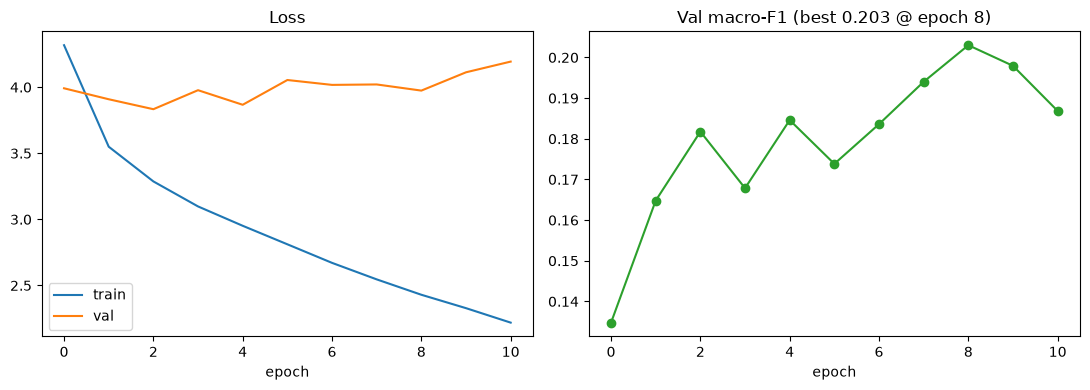

In [ ]:
tf.keras.backend.clear_session()
pmoe_model = build_pmoe(SIZE, len(classes), n_experts=N_EXPERTS, l=L_PATCHES, augmentation=AUG, backbone_fn=BB.last, lr=LR)
hist_pmoe, _ = run(pmoe_model, f'pmoe_{EPOCHS}epochs_{BACKBONE_ID}')

top_idx (64, 4, 8) = (images, experts, l patches);  patch grid (8, 8)
gate values of expert 0 on image 0: [0.172 0.157 0.154 0.119 0.117 0.099 0.096 0.085]  (they sum to 1.0 )


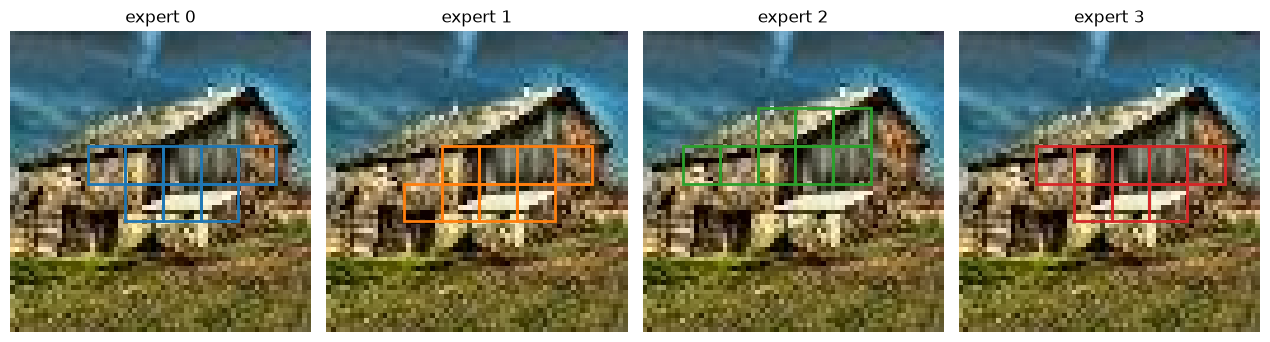

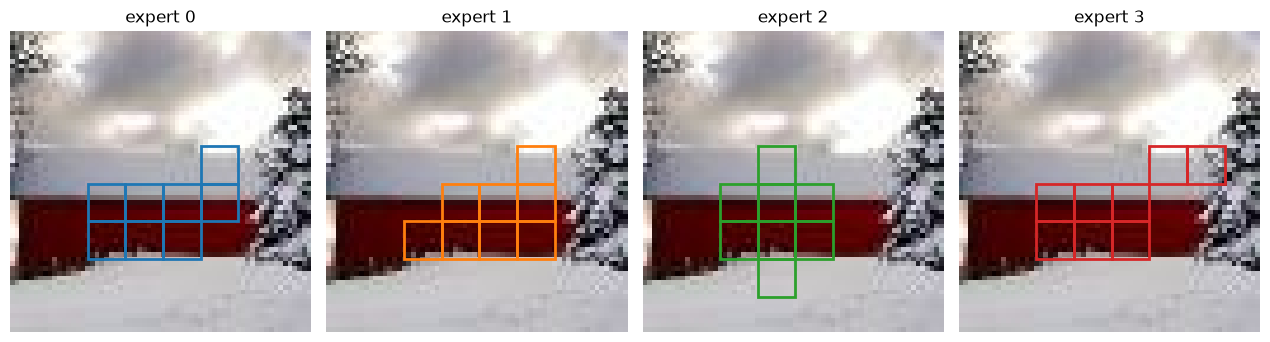

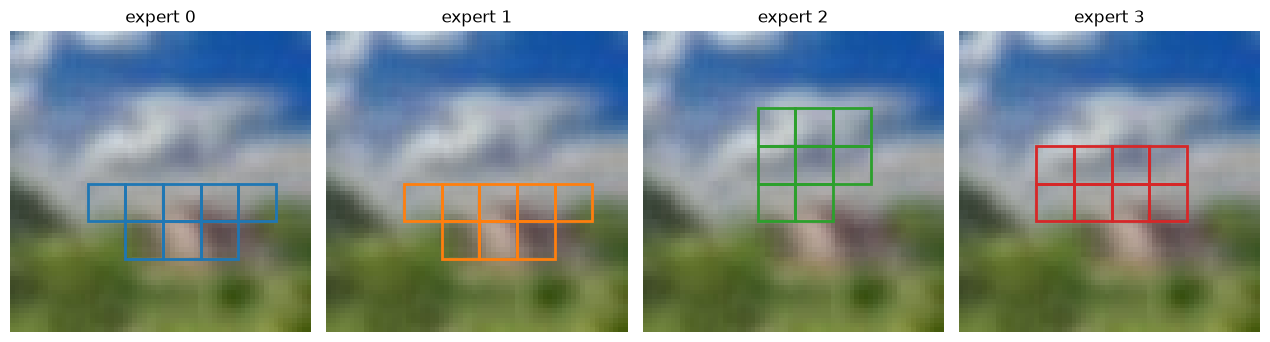

In [ ]:
# which patches does each expert pick? one row per image, one panel per expert
images, labels = next(iter(val))
top_idx, gates, grid = expert_choices(pmoe_model, images[:64])
print('top_idx', top_idx.shape, '= (images, experts, l patches);  patch grid', grid)
print('gate values of expert 0 on image 0:', gates[0, 0].round(3), ' (they sum to', gates[0, 0].sum().round(3), ')')

for i in range(3):
    plotting.show_expert_patches(images[i].numpy(), top_idx[i], grid)

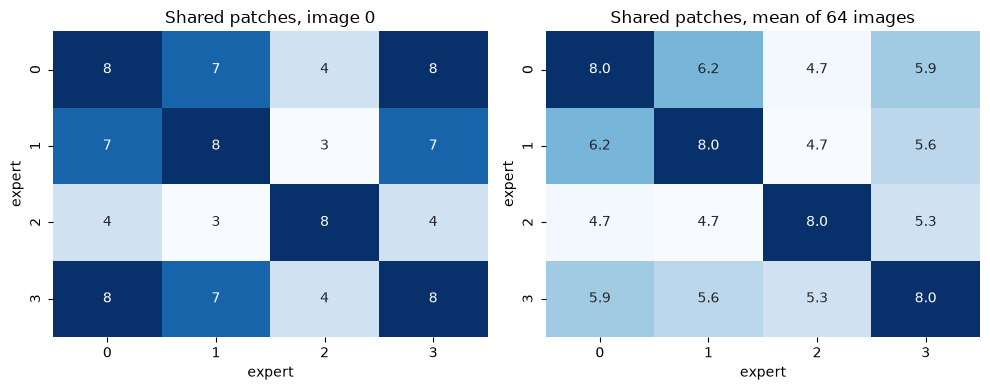

In [ ]:
# do the experts pick different patches? number of patches two experts share (the diagonal is l)
# big off-diagonal numbers = the routers did not specialise (pMoE has no balancing loss)
k = top_idx.shape[1]
def overlap(n):
    return np.array([[len(set(top_idx[n, a]) & set(top_idx[n, b])) for b in range(k)] for a in range(k)])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(overlap(0), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0])
ax[0].set(title='Shared patches, image 0', xlabel='expert', ylabel='expert')
sns.heatmap(np.mean([overlap(n) for n in range(len(top_idx))], axis=0), annot=True, fmt='.1f', cmap='Blues', cbar=False, ax=ax[1])
ax[1].set(title=f'Shared patches, mean of {len(top_idx)} images', xlabel='expert', ylabel='expert')
plt.tight_layout(); plt.show()

## 4. MGE (multi-depth experts)
Adapted from Zhang et al., ICCV 2019. One expert per backbone depth, each with its own loss:
```
s1 (32x32x64)   s2 (16x16x128)   s3 (8x8x256)
      |               |               |
   average                 average                  average          (each expert averages its own map)
   dropout                 dropout                  dropout
   Dense(200)         Dense(200)            Dense(200)
   expert_0              expert_1                expert_2
        \_____________|_______________/
              ensemble = mean of the three  (only used to measure the combination)
```
* A **diversity penalty** (weight `DIVERSITY_WEIGHT`) pushes the experts towards different predictions.
* The loss Keras prints is the sum of four cross-entropies plus the penalty, so it is **not comparable** with the loss of the other models. Compare accuracy and macro-F1.

Epoch 1/20


E0000 00:00:1795035789.197234     767 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/mge_1/trunk_1/spatial_dropout2d_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - ensemble_accuracy: 0.0820 - ensemble_loss: 4.7852 - expert_0_accuracy: 0.0181 - expert_0_loss: 5.2497 - expert_1_accuracy: 0.0269 - expert_1_loss: 5.0945 - expert_2_accuracy: 0.0959 - expert_2_loss: 4.5218 - loss: 19.7175  val macro-F1 0.1075
302/302 ━━━━━━━━━━━━━━━━━━━━ 36s 88ms/step - ensemble_accuracy: 0.0821 - ensemble_loss: 4.7845 - expert_0_accuracy: 0.0181 - expert_0_loss: 5.2496 - expert_1_accuracy: 0.0269 - expert_1_loss: 5.0943 - expert_2_accuracy: 0.0961 - expert_2_loss: 4.5208 - loss: 19.7164 - val_ensemble_accuracy: 0.1479 - val_ensemble_loss: 4.3700 - val_expert_0_accuracy: 0.0498 - val_expert_0_loss: 4.9162 - val_expert_1_accuracy: 0.0702 - val_expert_1_loss: 4.6872 - val_expert_2_accuracy: 0.1557 - val_expert_2_loss: 4.0550 - val_loss: 18.0843 - val_f1: 0.1075
Epoch 2/20
301/302 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - ensemble_accuracy: 0.1712 - ensemble_loss: 4.1589 - expert_0_accuracy: 0.0429 - expert_0_loss: 4.8831 - expert_1_a

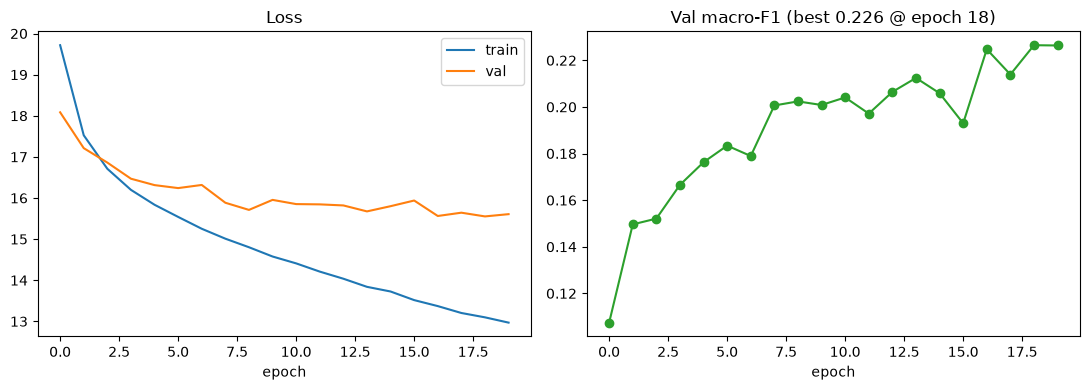

In [ ]:
tf.keras.backend.clear_session()
mge_model = build_mge(SIZE, len(classes), diversity_weight=DIVERSITY_WEIGHT, augmentation=AUG, backbone_fn=BB.maps, lr=LR)
hist_mge, _ = run(mge_model, f'mge_{EPOCHS}epochs_{BACKBONE_ID}')

How good is each MGE expert on its own, and what does averaging them give?

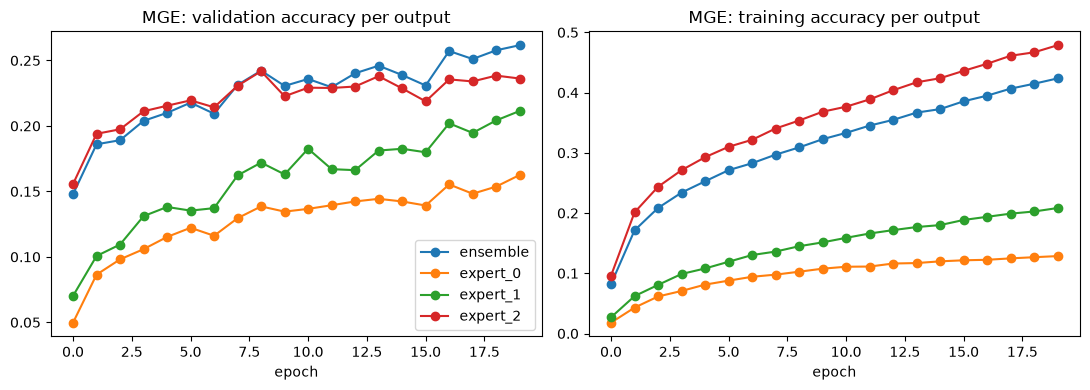

best val accuracy: {'ensemble': 0.2617, 'expert_0': 0.1626, 'expert_1': 0.2114, 'expert_2': 0.2418}


In [ ]:
# what does each expert achieve on its own?
h = hist_mge.history
outputs = ['ensemble', 'expert_0', 'expert_1', 'expert_2']

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name in outputs:
    ax[0].plot(h[f'val_{name}_accuracy'], marker='o', label=name)
    ax[1].plot(h[f'{name}_accuracy'], marker='o', label=name)
ax[0].set(title='MGE: validation accuracy per output', xlabel='epoch')
ax[1].set(title='MGE: training accuracy per output', xlabel='epoch')
ax[0].legend(); plt.tight_layout(); plt.show()
print('best val accuracy:', {n: round(max(h[f'val_{n}_accuracy']), 4) for n in outputs})

## Comparison
Loss (solid = validation, dashed = training), validation macro-F1 and validation accuracy of all four models. For MGE the *ensemble* output is used. Macro-F1 gives each of the 200 classes the same weight, so it is the stricter number.

In [ ]:
# the logs of the four models on this backbone (a model that was not trained in this session is read from its log)
names = ['cnn', 'moe', 'pmoe', 'mge']
runs = {m: f'{m}_{EPOCHS}epochs_{BACKBONE_ID}' for m in names}
logs = {m: pd.read_csv(os.path.join(HISTORY_DIR, f'{r}.csv')) for m, r in runs.items()
        if os.path.exists(os.path.join(HISTORY_DIR, f'{r}.csv'))}
plotting.plot_comparison({runs[m]: log for m, log in logs.items()})

nets = {'cnn': globals().get('cnn'), 'moe': globals().get('moe_model'), 'pmoe': globals().get('pmoe_model'), 'mge': globals().get('mge_model')}
rows = []
for name, h in logs.items():
    val_acc = h['val_ensemble_accuracy'] if 'val_ensemble_accuracy' in h else h['val_accuracy']
    train_acc = h['ensemble_accuracy'] if 'ensemble_accuracy' in h else h['accuracy']
    net = nets[name]
    rows.append(dict(model=name,
                     params=net.count_params() if net is not None else None,
                     trainable=int(sum(np.prod(w.shape) for w in net.trainable_weights)) if net is not None else None,
                     epochs_run=len(h), best_val_acc=val_acc.max(), best_val_f1=h['val_f1'].max(),
                     best_f1_epoch=int(h['val_f1'].values.argmax()) + 1,
                     last_train_acc=train_acc.iloc[-1], last_val_acc=val_acc.iloc[-1]))
pd.DataFrame(rows).set_index('model').round(4)

How to read the table: the *train* accuracy is measured with augmentation and dropout switched on, so it is lower than it would be on clean training images. A large gap between train and validation accuracy means overfitting. The kept weights are the epoch with the best validation loss, which is not always the epoch with the best macro-F1.

### What has been the same in every run so far
(The final numbers and the ranking of the models are left out until this version has been run.)
* **MoE:** the gate spreads the images almost evenly over the experts (the balance curve stays close to 1). (The balancing loss asks for this, so it is partly by design.)
* **MGE:** the deeper the expert, the better it is: `expert_0` (shallow) < `expert_1` < `expert_2` (deep).

In [ ]:
# save the head weights of the models trained in this session (best epoch, because EarlyStopping restores the best weights)
for name, model in nets.items():
    if model is None:
        continue
    weights_path = f'{MODELS_DIR}/{name}_{EPOCHS}epochs_{BACKBONE_ID}.weights.h5'
    model.save_weights(weights_path)
    print(f'saved {os.path.getsize(weights_path) / 1e6:.1f} MB -> {weights_path}')

    if USE_GITHUB:                               # Colab / pod: the disk disappears, so commit it as well
        push_files({weights_path: weights_path}, f'model weights: {name}_{EPOCHS}epochs_{BACKBONE_ID}')